First five rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinTh

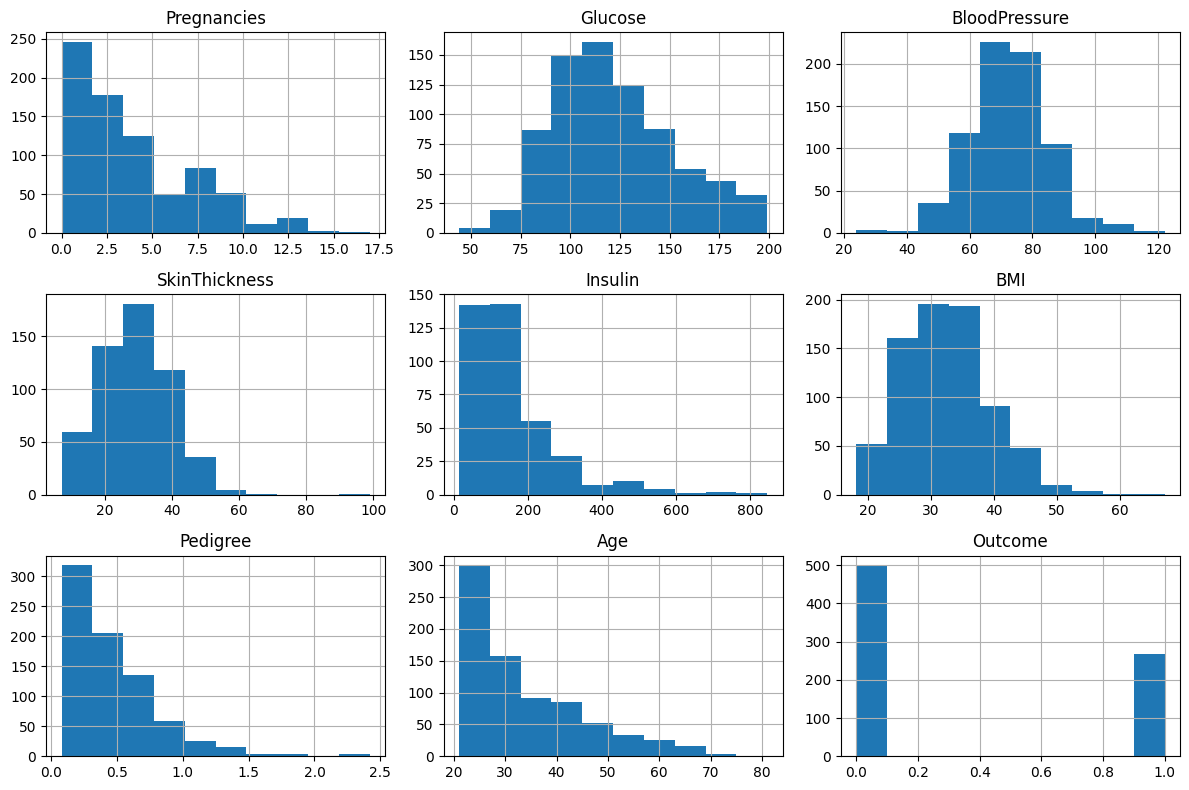


Diabetes Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


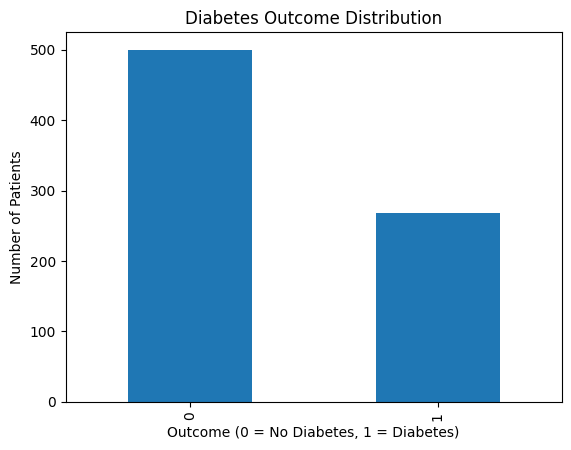


Training Samples: 614
Testing Samples: 154

Results for K = 3
Confusion Matrix:
[[78 22]
 [21 33]]

Results for K = 5
Confusion Matrix:
[[83 17]
 [21 33]]

Results for K = 7
Confusion Matrix:
[[82 18]
 [24 30]]

Results for K = 9
Confusion Matrix:
[[81 19]
 [21 33]]

Results for K = 11
Confusion Matrix:
[[82 18]
 [23 31]]

FINAL KNN COMPARISON
 K  Accuracy  Precision  Recall  F1-Score
 3    0.7208     0.6000  0.6111    0.6055
 5    0.7532     0.6600  0.6111    0.6346
 7    0.7273     0.6250  0.5556    0.5882
 9    0.7403     0.6346  0.6111    0.6226
11    0.7338     0.6327  0.5741    0.6019

Best K Value: 5
Best F1-Score: 0.6346

Final Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154


Fina

In [1]:

# Q20: Diabetes Classification Using KNN

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 2. Load dataset
df = pd.read_csv("diabetes.csv")

print("First five rows:")
print(df.head())

# 3. Dataset information
print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check invalid zero values
# These columns should not normally contain zero values
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("\nInvalid Zero Values:")
for col in zero_columns:
    print(col, ":", (df[col] == 0).sum())

# Replace invalid zeros with NaN
df[zero_columns] = df[zero_columns].replace(0, np.nan)

print("\nMissing Values After Replacing Zeros:")
print(df.isnull().sum())

# 6. Visualize feature distributions
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

# 7. Check target distribution
print("\nDiabetes Outcome Distribution:")
print(df["Outcome"].value_counts())

df["Outcome"].value_counts().plot(
    kind="bar",
    title="Diabetes Outcome Distribution"
)
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.show()

# 8. Select features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# 9. Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# 10. Try different K values
k_values = [3, 5, 7, 9, 11]

results = []

best_k = None
best_f1 = -1
best_model = None

for k in k_values:

    # Create KNN pipeline
    model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Store results
    results.append({
        "K": k,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4)
    })

    # Display confusion matrix
    print("\nResults for K =", k)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    # Select best model based on F1-score
    if f1 > best_f1:
        best_f1 = f1
        best_k = k
        best_model = model

# 11. Display comparison table
comparison = pd.DataFrame(results)

print("\nFINAL KNN COMPARISON")
print(comparison.to_string(index=False))

# 12. Display best K
print("\nBest K Value:", best_k)
print("Best F1-Score:", round(best_f1, 4))

# 13. Final classification report
final_predictions = best_model.predict(X_test)

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))
